# **Connect to GEE**

In [1]:
!pip install -q --upgrade --pre xee
!pip install -q -U geemap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.5/2.5 MB 9.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 53.5 MB/s eta 0:00:00


In [2]:
import ee

In [3]:
ee.Authenticate()
ee.Initialize(
    project = 'ee-amirhosseinahrari',
    opt_url = 'https://earthengine-highvolume.googleapis.com'
)

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


# **Study Area**

In [4]:
import geemap

In [5]:
map = geemap.Map(basemap = 'Esri.WorldTopoMap')
map

Map(center=[0, 0], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', transp…

In [6]:
point = map.draw_last_feature.geometry()
point

ee.Geometry({
  "functionInvocationValue": {
    "functionName": "Feature.geometry",
    "arguments": {
      "feature": {
        "functionInvocationValue": {
          "functionName": "Feature",
          "arguments": {
            "geometry": {
              "functionInvocationValue": {
                "functionName": "GeometryConstructors.Point",
                "arguments": {
                  "coordinates": {
                    "constantValue": [
                      -124.980469,
                      53.644638
                    ]
                  }
                }
              }
            }
          }
        }
      }
    }
  }
})

In [7]:
roi = (
    ee.FeatureCollection("FAO/GAUL_SIMPLIFIED_500m/2025/level1")
    .filterBounds(point)
    .geometry()
)

In [8]:
map.addLayer(roi, {},'roi')

# **ERA5 Image Collection**

In [9]:
era5 = (
    ee.ImageCollection("ECMWF/ERA5_LAND/DAILY_AGGR")
    .filterDate('2020','2025')
    .select(
        'temperature_2m_max',
        'total_precipitation_sum',
        'u_component_of_wind_10m',
        'v_component_of_wind_10m',
        'dewpoint_temperature_2m'
    )
)

In [10]:
era5.size()

In [11]:
era5.limit(10)

# **to Xarray**

In [12]:
from xee import helpers
from shapely.geometry import shape
import xarray as xr

In [13]:
grid = helpers.fit_geometry(
    geometry = shape(roi.getInfo()),
    grid_crs = 'EPSG:4326',
    grid_scale = (0.11, -0.11)
)

In [14]:
ds = xr.open_dataset(
    era5,
    engine = 'ee',
    **grid,
    chunks = 'auto'
)

In [16]:
from dask.diagnostics import ProgressBar

In [17]:
with ProgressBar():
  ds = ds.compute()

[                                        ] | 0% Completed | 18.37 s

[##########################              ] | 66% Completed | 75.44 s

[##################################      ] | 86% Completed | 100.59 s

[########################################] | 100% Completed | 101.43 s


In [20]:
temp_max = ds['temperature_2m_max'] - 273.15
temp_max.attrs['units'] = 'degC'

In [22]:
pr = ds['total_precipitation_sum'] * 1000
pr.attrs['units'] = 'mm/day'

In [23]:
import numpy as np

In [24]:
ucom = ds['u_component_of_wind_10m']
vcom = ds['v_component_of_wind_10m']
ws = np.sqrt((ucom ** 2) + (vcom ** 2))
ws.attrs['units'] = 'm/s'

In [26]:
dew = ds['dewpoint_temperature_2m'] - 273.15
num = np.exp((17.625 * dew)/(243.04 + dew))
den = np.exp((17.625 * temp_max)/(243.04 + temp_max))
rh = (num / den) * 100

In [27]:
rh.attrs['units'] = '%'

# **Fire Index**

In [29]:
!pip install -q xclim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.9/386.9 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 199.5/199.5 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.8/80.8 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 22.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 326.5/326.5 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.2/58.2 kB 3.0 MB/s eta 0:00:00


In [30]:
from xclim.indicators.atmos import cffwis_indices

In [31]:
ds.y.attrs['units'] = 'degree_north'

In [34]:
ws.attrs['units'] = 'm/s'

dc, dmc, ffmc, isi, bui, fwi = cffwis_indices(
    tas = temp_max,
    pr = pr,
    sfcWind = ws,
    hurs = rh,
    lat = ds.y
)

# **Clip**

In [35]:
roi_gdf = geemap.ee_to_gdf(ee.FeatureCollection(roi))

In [37]:
!pip install -q rioxarray
import rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 755.8 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 7.1 MB/s eta 0:00:00


In [38]:
fwi_clip = fwi.rio.clip(roi_gdf.geometry, roi_gdf.crs)

# **Visualization**

In [39]:
fwi_mean = fwi_clip.mean(dim = 'time')

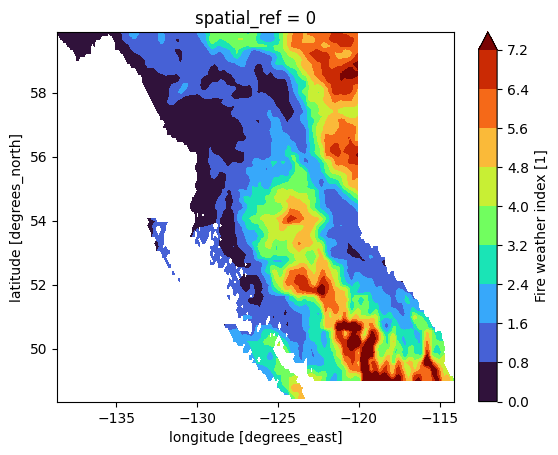

In [42]:
fwi_mean.plot.contourf(
    robust = True,
    cmap = 'turbo',
    levels = 10
)

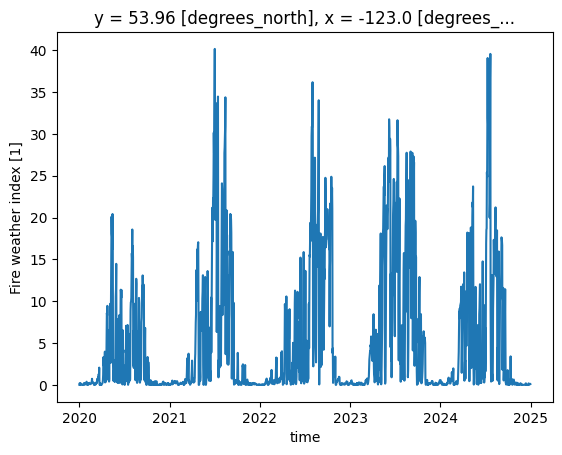

In [47]:
fwi_clip.sel(
    x = -123,
    y = 54,
    method = 'nearest'
).plot()

In [43]:
fwi_annual = fwi_clip.resample(time = 'YE').mean('time')

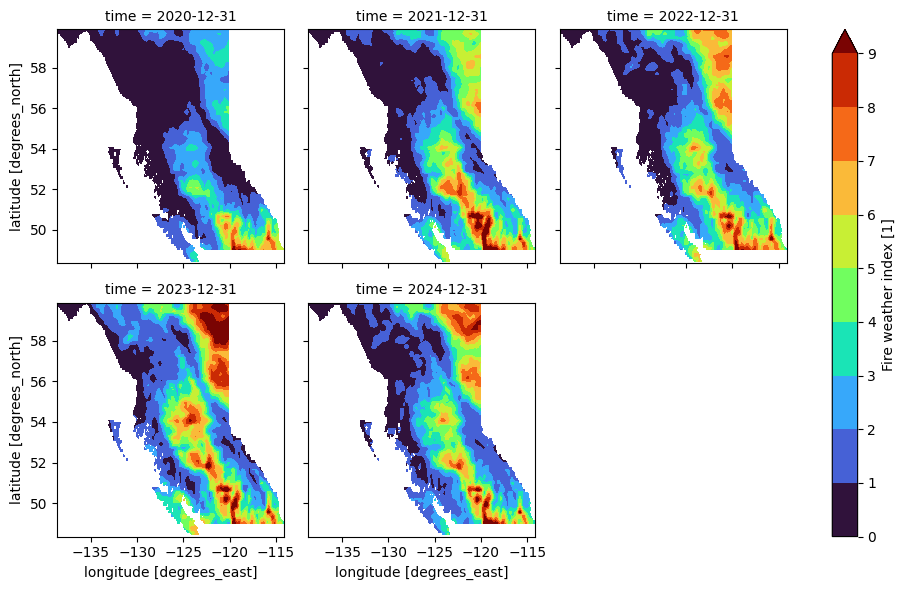

In [46]:
fwi_annual.plot.contourf(
    col = 'time',
    robust = True,
    cmap = 'turbo',
    levels = 10,
    col_wrap = 3
)